# Phase 3 – Churn KPI Calculations


## Objective
The objective of this phase is to calculate the key business metrics (KPIs) related to customer churn, revenue and service quality, using the cleaned NexaTel data.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
dark_color = "#0B3C5D"
light_color = "#4FA3D1"

customers = pd.read_csv("customers_cleaned.csv", parse_dates=["date_of_birth", "acquisition_date", "churn_date"])
subscriptions = pd.read_csv("subscriptions_cleaned.csv", parse_dates=["start_date", "end_date"])
support_tickets = pd.read_csv("support_tickets_cleaned.csv", parse_dates=["created_date", "resolution_date"])
contracts = pd.read_csv("contracts_cleaned.csv", parse_dates=["start_date", "end_date"])
billing = pd.read_csv("billing_cleaned.csv", parse_dates=["billing_date", "due_date"])

print(customers.shape, subscriptions.shape, support_tickets.shape, contracts.shape, billing.shape)

(19000, 26) (20523, 8) (31490, 11) (10607, 9) (114969, 9)


## KPI 1 and KPI 2 – Customer Churn Rate and Customer Retention Rate

**Customer Churn Rate** = Customers Lost / Customers at Start × 100

**Customer Retention Rate** = (Customers at End − New Customers) / Customers at Start × 100

The metrics are calculated for every month from April 2024 to March 2026. The latest month in the data is March 2026.

In [2]:
months = pd.period_range("2024-04", "2026-03", freq="M")

rows = []
for m in months:
    month_start = m.start_time
    month_end = m.end_time.normalize()

    # customers at the start: joined before the month and had not churned yet
    start = ((customers["acquisition_date"] < month_start) & (customers["churn_date"].isnull() | (customers["churn_date"] >= month_start))).sum()
    # new customers and lost customers during the month
    new = ((customers["acquisition_date"] >= month_start) & (customers["acquisition_date"] <= month_end)).sum()
    lost = ((customers["churn_date"] >= month_start) & (customers["churn_date"] <= month_end)).sum()
    end = start + new - lost

    rows.append([str(m), start, new, lost, end])

monthly = pd.DataFrame(rows, columns=["month", "start", "new", "lost", "end"])
monthly["churn_rate_%"] = (monthly["lost"] / monthly["start"] * 100).round(2)
monthly["retention_rate_%"] = ((monthly["end"] - monthly["new"]) / monthly["start"] * 100).round(2)
print(monthly.tail(6))

latest = monthly.iloc[-1]
print("Month:", latest["month"])
print("Customers at start:", latest["start"], "| Lost:", latest["lost"], "| New:", latest["new"], "| At end:", latest["end"])
print("Churn rate (latest month):", latest["churn_rate_%"], "%")
print("Churn rate (average of last 12 months):", round(monthly.tail(12)["churn_rate_%"].mean(), 2), "%")
print("Retention rate (latest month):", latest["retention_rate_%"], "%")
print("Retention rate (average of last 12 months):", round(monthly.tail(12)["retention_rate_%"].mean(), 2), "%")

      month  start  new  lost    end  churn_rate_%  retention_rate_%
18  2025-10  15714  135    94  15755          0.60             99.40
19  2025-11  15755  113   113  15755          0.72             99.28
20  2025-12  15755  106   109  15752          0.69             99.31
21  2026-01  15752  113   124  15741          0.79             99.21
22  2026-02  15741   90   143  15688          0.91             99.09
23  2026-03  15688    4   198  15494          1.26             98.74
Month: 2026-03
Customers at start: 15688 | Lost: 198 | New: 4 | At end: 15494
Churn rate (latest month): 1.26 %
Churn rate (average of last 12 months): 0.67 %
Retention rate (latest month): 98.74 %
Retention rate (average of last 12 months): 99.33 %


Trend Chart

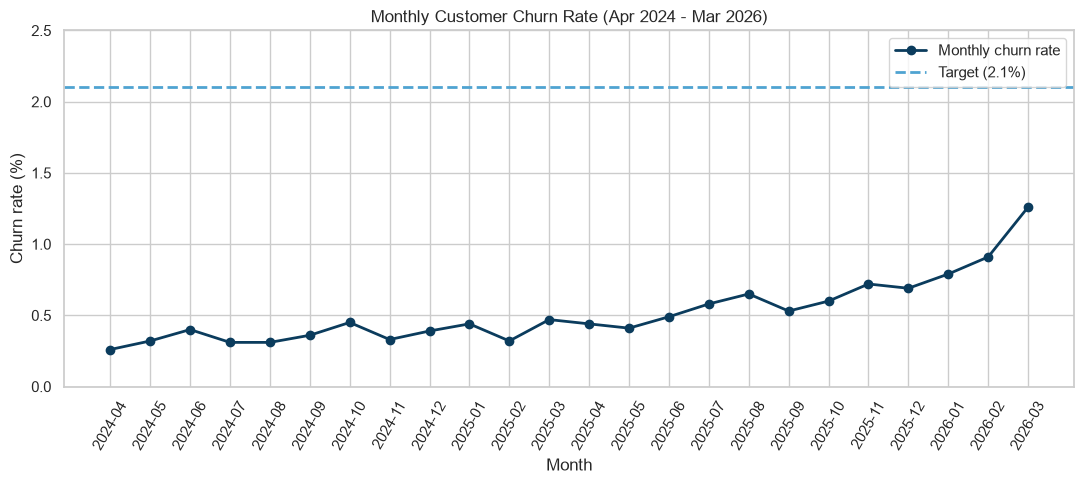

In [3]:
plt.figure(figsize=(11, 5))
plt.plot(monthly["month"], monthly["churn_rate_%"], color=dark_color, marker="o", linewidth=2, label="Monthly churn rate")
plt.axhline(2.1, color=light_color, linestyle="--", linewidth=2, label="Target (2.1%)")
plt.xticks(rotation=60)
plt.title("Monthly Customer Churn Rate (Apr 2024 - Mar 2026)")
plt.xlabel("Month")
plt.ylabel("Churn rate (%)")
plt.ylim(0, 2.5)
plt.legend()
plt.tight_layout()
plt.savefig("kpi1_monthly_churn_trend.png", dpi=150)
plt.show()

### Observation – KPI 1: Churn Rate
In March 2026, 198 of the 15,688 customers at the start of the month left, giving a monthly churn rate of 1.26%. The average over the last 12 months is 0.67%. Both are below the 2.1% monthly target, but churn is rising quickly: it has grown almost five times, from 0.26% in April 2024 to 1.26% in March 2026, and the increase accelerated in the last three months. If this trend continues, the company could cross the 2.1% target within a few months.

### Observation – KPI 2: Retention Rate
The retention rate for March 2026 is 98.74%, down from 99.74% in April 2024. The average over the last 12 months is 99.33%. Retention is still high, but it is falling month by month as churn rises, which supports the need for stronger retention action.

## KPI 3 – ARPU (Average Revenue Per User)

"ARPU" = Total Recurring Revenue / Active Subscribers

Total recurring revenue (MRR) is the sum of the monthly charges of all active subscriptions that belong to currently active customers. Active customers at the end of March 2026 are used as the subscriber base.

Active subscriptions: 17017
customer_status
Active     16766
Churned      251
Name: count, dtype: int64
Total recurring revenue (MRR): Rs 14719446
Active customers: 15494
ARPU: Rs 950.01
customer_segment
Enterprise    4088.30
Premium        909.09
Value          496.05
Mass           339.43
dtype: float64


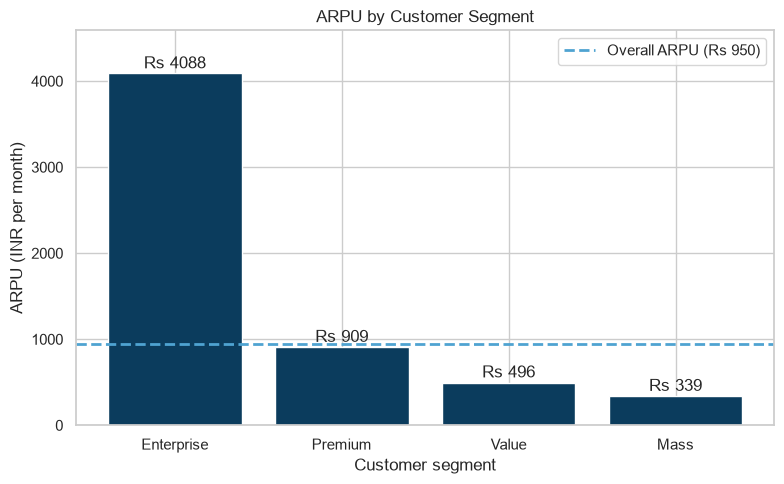

In [4]:
# active subscriptions, with the status and segment of the customer who owns them
active_subs = subscriptions[subscriptions["subscription_status"] == "Active"]
print("Active subscriptions:", len(active_subs))

sub_customer = active_subs.merge(customers[["customer_id", "customer_status", "customer_segment"]], on="customer_id", how="left")
print(sub_customer["customer_status"].value_counts())

# only count subscriptions of customers who are still active
recurring = sub_customer[sub_customer["customer_status"] == "Active"]
mrr = recurring["monthly_charge_inr"].sum()
active_customers = (customers["customer_status"] == "Active").sum()
arpu = mrr / active_customers

print("Total recurring revenue (MRR): Rs", round(mrr))
print("Active customers:", active_customers)
print("ARPU: Rs", round(arpu, 2))

# ARPU for each segment
active_by_segment = customers[customers["customer_status"] == "Active"].groupby("customer_segment").size()
mrr_by_segment = recurring.groupby("customer_segment")["monthly_charge_inr"].sum()
arpu_by_segment = (mrr_by_segment / active_by_segment).round(2).sort_values(ascending=False)
print(arpu_by_segment)

plt.figure(figsize=(8, 5))
plt.bar(arpu_by_segment.index, arpu_by_segment.values, color=dark_color)
for i in range(len(arpu_by_segment)):
    plt.text(i, arpu_by_segment.values[i] + 60, "Rs " + str(round(arpu_by_segment.values[i])), ha="center", fontsize=12)
plt.axhline(arpu, color=light_color, linestyle="--", linewidth=2, label="Overall ARPU (Rs " + str(round(arpu)) + ")")
plt.ylim(0, arpu_by_segment.max() + 500)
plt.title("ARPU by Customer Segment")
plt.xlabel("Customer segment")
plt.ylabel("ARPU (INR per month)")
plt.legend()
plt.tight_layout()
plt.savefig("kpi3_arpu_by_segment.png", dpi=150)
plt.show()

### Observation
The company earns about ₹14.72 million in monthly recurring revenue from 15,494 active customers, which gives an ARPU of ₹950.01 per customer per month. ARPU differs widely by segment: Enterprise customers pay ₹4,088 per month on average, about twelve times more than Mass customers (₹339). Premium customers (₹909) are close to the overall average, while Value (₹496) and Mass (₹339) are well below it. Enterprise customers are only 1,224 of the 15,494 active customers but generate about a third of the monthly revenue (₹5.0 million), so retaining them is especially important.

## KPI 4 – Customer Lifetime Value (CLV)

"CLV" = ARPU × Gross Margin % × (1 / Monthly Churn Rate)

**Assumption:** the dataset does not contain a gross margin, so a gross margin of **70%** is assumed. The monthly churn rate is the average over the last 12 months (April 2025 to March 2026), calculated separately for each segment.

      segment  customer_months  lost  monthly_churn_%
0        Mass            26560   288            1.084
1       Value            60338   469            0.777
2     Premium            86459   444            0.514
3  Enterprise            14677    64            0.436
Overall monthly churn: 0.673 %
Overall CLV: Rs 98849
      segment     ARPU  monthly_churn_%  lifetime_months       CLV
3  Enterprise  4088.30            0.436            229.4  656378.0
2     Premium   909.09            0.514            194.6  123806.0
1       Value   496.05            0.777            128.7   44689.0
0        Mass   339.43            1.084             92.3   21919.0


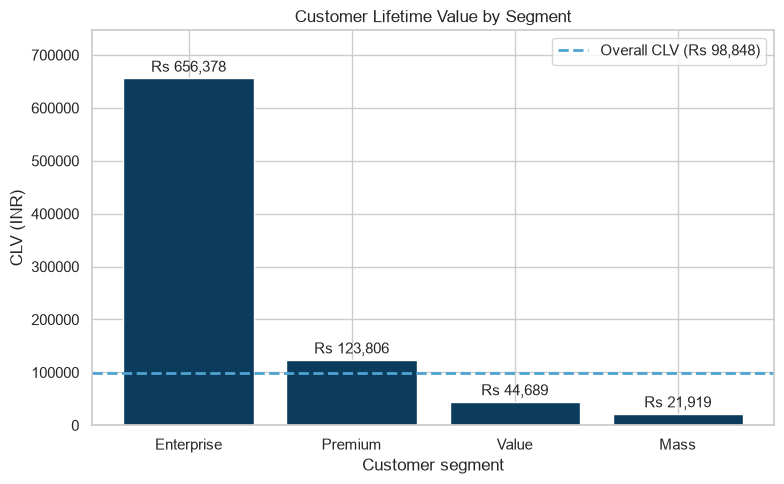

In [5]:
gross_margin = 0.70   # assumption, not in the dataset

# monthly churn for each segment over the last 12 months
rows = []
for seg in ["Mass", "Value", "Premium", "Enterprise"]:
    seg_customers = customers[customers["customer_segment"] == seg]
    total_start = 0
    total_lost = 0
    for m in pd.period_range("2025-04", "2026-03", freq="M"):
        month_start = m.start_time
        month_end = m.end_time.normalize()
        total_start = total_start + ((seg_customers["acquisition_date"] < month_start) & (seg_customers["churn_date"].isnull() | (seg_customers["churn_date"] >= month_start))).sum()
        total_lost = total_lost + ((seg_customers["churn_date"] >= month_start) & (seg_customers["churn_date"] <= month_end)).sum()
    rows.append([seg, total_start, total_lost])

churn_table = pd.DataFrame(rows, columns=["segment", "customer_months", "lost"])
churn_table["monthly_churn_%"] = (churn_table["lost"] / churn_table["customer_months"] * 100).round(3)
overall_churn = churn_table["lost"].sum() / churn_table["customer_months"].sum() * 100
print(churn_table)
print("Overall monthly churn:", round(overall_churn, 3), "%")

# overall CLV
clv_overall = arpu * gross_margin * (1 / (overall_churn / 100))
print("Overall CLV: Rs", round(clv_overall))

# CLV by segment
churn_table["ARPU"] = churn_table["segment"].map(arpu_by_segment)
churn_table["CLV"] = (churn_table["ARPU"] * gross_margin * (1 / (churn_table["monthly_churn_%"] / 100))).round(0)
churn_table["lifetime_months"] = (1 / (churn_table["monthly_churn_%"] / 100)).round(1)
clv_table = churn_table.sort_values("CLV", ascending=False)
print(clv_table[["segment", "ARPU", "monthly_churn_%", "lifetime_months", "CLV"]])

plt.figure(figsize=(8, 5))
plt.bar(clv_table["segment"], clv_table["CLV"], color=dark_color)
for i in range(len(clv_table)):
    plt.text(i, clv_table["CLV"].values[i] + 12000, "Rs " + format(int(clv_table["CLV"].values[i]), ","), ha="center", fontsize=11)
plt.axhline(clv_overall, color=light_color, linestyle="--", linewidth=2, label="Overall CLV (Rs " + format(int(clv_overall), ",") + ")")
plt.ylim(0, clv_table["CLV"].max() + 90000)
plt.title("Customer Lifetime Value by Segment")
plt.xlabel("Customer segment")
plt.ylabel("CLV (INR)")
plt.legend()
plt.tight_layout()
plt.savefig("kpi4_clv_by_segment.png", dpi=150)
plt.show()

### Observation
The overall Customer Lifetime Value is about ₹98,849, using an assumed gross margin of 70% and an average monthly churn of 0.67%. CLV varies enormously by segment: Enterprise customers are worth about ₹656,000, Premium customers about ₹124,000, Value customers about ₹45,000 and Mass customers about ₹22,000. A Premium customer is therefore worth more than five times a Mass customer, because Premium customers pay more per month and also stay longer (an expected lifetime of about 195 months compared with 92 months for Mass). These values depend on the assumed margin and on current churn, which has been rising, so they should be read as estimates: using the latest monthly churn of 1.26% would give an overall CLV of roughly ₹52,800. Retention spending is clearly most justified for Enterprise and Premium customers.

## KPI 5 – Revenue Lost to Churn

**Revenue Lost to Churn** = Churned Customers × their ARPU

The ARPU of a churned customer is the total monthly charge of all the subscriptions they had. The result is the monthly revenue that was lost when these customers left.

Churned customers: 3506
ARPU of churned customers: Rs 731.94
Monthly revenue lost: Rs 2566181
Annual revenue lost: Rs 30794172
                  churned_customers  monthly_revenue_lost  avg_charge  share_%
customer_segment                                                              
Premium                        1283             1277722.0      995.89     49.8
Value                          1275              656054.0      514.55     25.6
Enterprise                      166              381593.0     2298.75     14.9
Mass                            782              250812.0      320.73      9.8
Last 12 months: customers 1265 | monthly loss Rs 900101


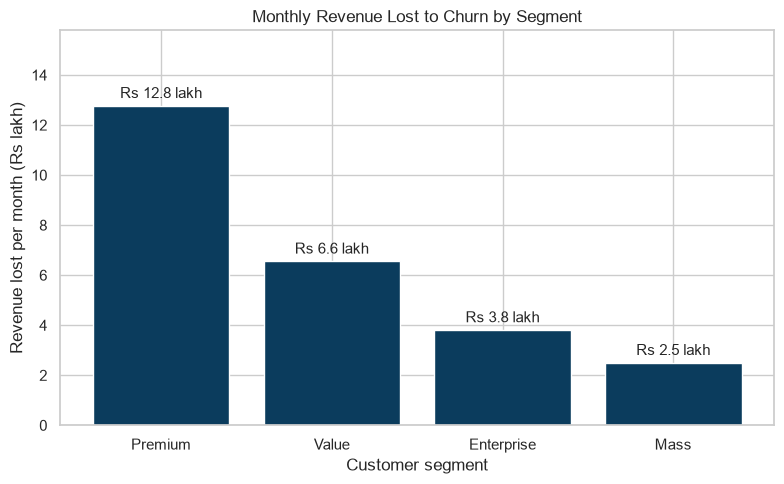

In [6]:
# total monthly charge of every customer (sum of all their subscriptions)
monthly_charge = subscriptions.groupby("customer_id")["monthly_charge_inr"].sum().reset_index(name="monthly_charge")
data = customers.merge(monthly_charge, on="customer_id", how="left")

churned = data[data["customer_status"] == "Churned"]
churned_count = len(churned)
churned_arpu = churned["monthly_charge"].mean()
monthly_loss = churned_count * churned_arpu

print("Churned customers:", churned_count)
print("ARPU of churned customers: Rs", round(churned_arpu, 2))
print("Monthly revenue lost: Rs", round(monthly_loss))
print("Annual revenue lost: Rs", round(monthly_loss * 12))

# revenue lost by segment
loss_seg = churned.groupby("customer_segment").agg(churned_customers=("customer_id", "count"),
                                                    monthly_revenue_lost=("monthly_charge", "sum"))
loss_seg["avg_charge"] = (loss_seg["monthly_revenue_lost"] / loss_seg["churned_customers"]).round(2)
loss_seg["share_%"] = (loss_seg["monthly_revenue_lost"] / loss_seg["monthly_revenue_lost"].sum() * 100).round(1)
loss_seg = loss_seg.sort_values("monthly_revenue_lost", ascending=False)
print(loss_seg)

# only the customers who churned in the last 12 months
last12 = churned[(churned["churn_date"] >= "2025-04-01") & (churned["churn_date"] <= "2026-03-31")]
print("Last 12 months: customers", len(last12), "| monthly loss Rs", round(last12["monthly_charge"].sum()))

plt.figure(figsize=(8, 5))
plt.bar(loss_seg.index, loss_seg["monthly_revenue_lost"] / 100000, color=dark_color)
for i in range(len(loss_seg)):
    plt.text(i, loss_seg["monthly_revenue_lost"].values[i] / 100000 + 0.3, "Rs " + str(round(loss_seg["monthly_revenue_lost"].values[i] / 100000, 1)) + " lakh", ha="center", fontsize=11)
plt.ylim(0, loss_seg["monthly_revenue_lost"].max() / 100000 + 3)
plt.title("Monthly Revenue Lost to Churn by Segment")
plt.xlabel("Customer segment")
plt.ylabel("Revenue lost per month (Rs lakh)")
plt.tight_layout()
plt.savefig("kpi5_revenue_lost_by_segment.png", dpi=150)
plt.show()

### Observation
The 3,506 customers who have churned were each paying about ₹732 per month, so churn has removed about ₹2.57 million of monthly recurring revenue, or about ₹30.8 million per year. This is equal to roughly 17.4% of today's monthly recurring revenue. Premium customers account for the largest share of the lost revenue (49.8%), followed by Value (25.6%), Enterprise (14.9%) and Mass (9.8%). Although Mass customers churn at the highest rate, they cost the least in revenue (₹0.25 million per month), while Premium customers lose the most because there are many of them and each pays a fairly high charge. Looking only at the last 12 months, the 1,265 customers who left took about ₹0.90 million of monthly revenue with them. Retention spending should therefore be directed by revenue at risk and not only by churn rate.

## KPI 6 – Monthly Recurring Revenue (MRR)

**MRR** = Sum of active recurring charges

Only active subscriptions that belong to currently active customers are counted.

MRR: Rs 14719446
Annual run rate (MRR x 12): Rs 176633352
                        MRR  share_%
customer_segment                    
Premium           6544524.0     44.5
Enterprise        5004084.0     34.0
Value             2441062.0     16.6
Mass               729776.0      5.0
                       MRR  share_%
product_line                       
Enterprise       4828509.0     32.8
Prepaid Mobile   2914832.0     19.8
Postpaid Mobile  2834877.0     19.3
Fiber Broadband  2106814.0     14.3
5G               1194178.0      8.1
OTT Bundles       411437.0      2.8
Smart Home        253224.0      1.7
IoT Solutions     175575.0      1.2
Monthly revenue lost to churn as % of MRR: 17.4 %


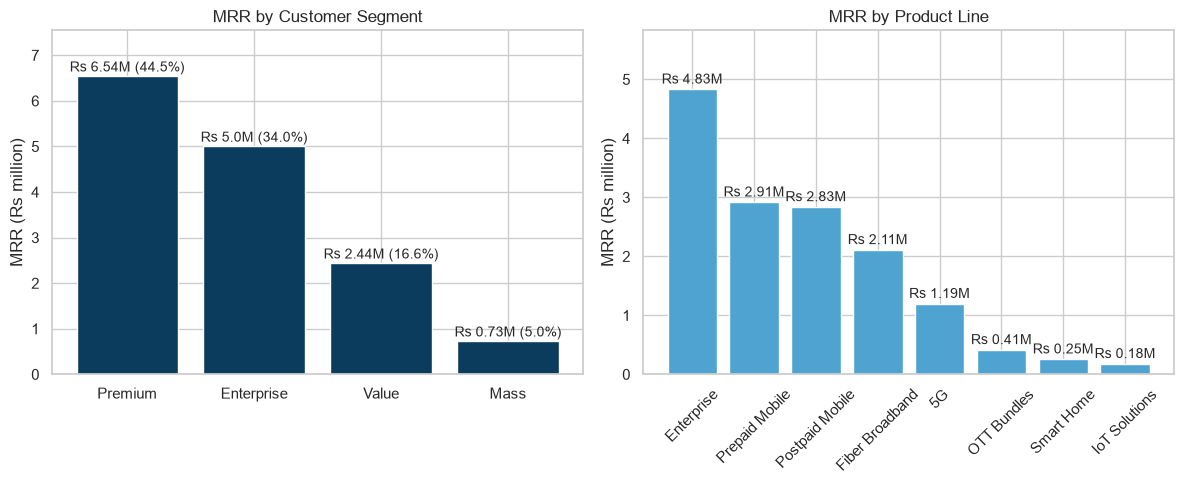

In [7]:
active_subs = subscriptions[subscriptions["subscription_status"] == "Active"]
recurring = active_subs.merge(customers[["customer_id", "customer_status", "customer_segment", "product_line"]], on="customer_id", how="left")
recurring = recurring[recurring["customer_status"] == "Active"]

mrr = recurring["monthly_charge_inr"].sum()
print("MRR: Rs", round(mrr))
print("Annual run rate (MRR x 12): Rs", round(mrr * 12))

# MRR by segment
mrr_seg = recurring.groupby("customer_segment")["monthly_charge_inr"].sum().sort_values(ascending=False)
mrr_share = (mrr_seg / mrr * 100).round(1)
print(pd.DataFrame({"MRR": mrr_seg.round(0), "share_%": mrr_share}))

# MRR by product line
mrr_pl = recurring.groupby("product_line")["monthly_charge_inr"].sum().sort_values(ascending=False)
print(pd.DataFrame({"MRR": mrr_pl.round(0), "share_%": (mrr_pl / mrr * 100).round(1)}))

print("Monthly revenue lost to churn as % of MRR:", round(monthly_loss / mrr * 100, 1), "%")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(mrr_seg.index, mrr_seg.values / 1000000, color=dark_color)
for i in range(len(mrr_seg)):
    axes[0].text(i, mrr_seg.values[i] / 1000000 + 0.1, "Rs " + str(round(mrr_seg.values[i] / 1000000, 2)) + "M (" + str(mrr_share.values[i]) + "%)", ha="center", fontsize=10)
axes[0].set_ylim(0, mrr_seg.max() / 1000000 + 1)
axes[0].set_title("MRR by Customer Segment")
axes[0].set_ylabel("MRR (Rs million)")

axes[1].bar(mrr_pl.index, mrr_pl.values / 1000000, color=light_color)
for i in range(len(mrr_pl)):
    axes[1].text(i, mrr_pl.values[i] / 1000000 + 0.1, "Rs " + str(round(mrr_pl.values[i] / 1000000, 2)) + "M", ha="center", fontsize=10)
axes[1].set_ylim(0, mrr_pl.max() / 1000000 + 1)
axes[1].set_title("MRR by Product Line")
axes[1].set_ylabel("MRR (Rs million)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("kpi6_mrr.png", dpi=150)
plt.show()

### Observation
The company's monthly recurring revenue is about ₹14.72 million, which is an annual run rate of about ₹176.6 million. Revenue is concentrated in the top segments: Premium contributes 44.5% and Enterprise 34.0%, so these two segments together bring in 78.5% of MRR while making up about 54% of active customers. Mass customers, in contrast, are about 14% of active customers but only 5.0% of MRR. By product line, Enterprise (32.8%), Prepaid Mobile (19.8%) and Postpaid Mobile (19.3%) are the largest contributors. The monthly revenue already lost to churn (₹2.57 million) equals 17.4% of the current MRR, which shows how much revenue is at stake if churn keeps rising.

## KPI 7 – First Contact Resolution (FCR)

**FCR** = Tickets Resolved on First Contact / Total Tickets × 100

Target: above 78%. Tickets that are still pending, escalated or reopened are not resolved, so they count as not resolved on first contact.

Total tickets: 31490
Resolved on first contact: 12726
FCR: 40.41 %
status
Resolved     18124
Pending       8450
Escalated     2526
Reopened      2390
Name: count, dtype: int64
FCR among resolved tickets only: 70.22 %
category
Payment Issue       38.76
Device Support      38.89
Plan Change         39.72
SIM/Activation      39.77
Roaming             39.86
Call Drop           39.94
Recharge Failure    40.16
Slow Data Speed     40.59
Fiber Downtime      41.22
Account Update      41.51
Network Issue       42.11
Billing Dispute     42.36
Name: first_contact_resolution, dtype: float64
first_contact_resolution
No     22.10
Yes    18.83
Name: customer_status, dtype: float64


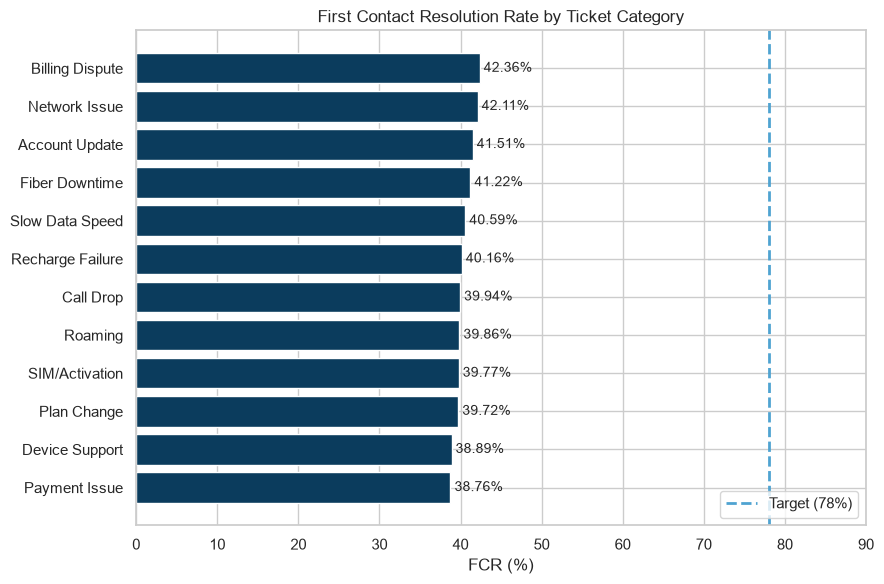

In [8]:
total_tickets = len(support_tickets)
fcr_tickets = (support_tickets["first_contact_resolution"] == "Yes").sum()
fcr = fcr_tickets / total_tickets * 100

print("Total tickets:", total_tickets)
print("Resolved on first contact:", fcr_tickets)
print("FCR:", round(fcr, 2), "%")

# status of all tickets
print(support_tickets["status"].value_counts())

# FCR if we only look at tickets that were resolved
resolved_tickets = support_tickets[support_tickets["status"] == "Resolved"]
fcr_resolved = (resolved_tickets["first_contact_resolution"] == "Yes").mean() * 100
print("FCR among resolved tickets only:", round(fcr_resolved, 2), "%")

# FCR by ticket category
fcr_category = support_tickets.groupby("category")["first_contact_resolution"].apply(lambda s: round((s == "Yes").mean() * 100, 2)).sort_values()
print(fcr_category)

# do tickets that were not fixed first time belong to customers who churned more?
tickets_customers = support_tickets.merge(customers[["customer_id", "customer_status"]], on="customer_id", how="left")
churn_by_fcr = tickets_customers.groupby("first_contact_resolution")["customer_status"].apply(lambda s: round((s == "Churned").mean() * 100, 2))
print(churn_by_fcr)

plt.figure(figsize=(9, 6))
plt.barh(fcr_category.index, fcr_category.values, color=dark_color)
for i in range(len(fcr_category)):
    plt.text(fcr_category.values[i] + 0.5, i, str(fcr_category.values[i]) + "%", va="center", fontsize=10)
plt.axvline(78, color=light_color, linestyle="--", linewidth=2, label="Target (78%)")
plt.xlim(0, 90)
plt.title("First Contact Resolution Rate by Ticket Category")
plt.xlabel("FCR (%)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("kpi7_fcr_by_category.png", dpi=150)
plt.show()

### Observation
Only 40.41% of the 31,490 support tickets were resolved on first contact, far below the 78% target. Even when only resolved tickets are considered, FCR is 70.22%, still under the target. A large share of tickets is still open: 8,450 are pending, 2,526 escalated and 2,390 reopened (42.44% of all tickets). The problem is spread across all categories (38.76% to 42.36%), so it appears to be a general process issue and not a problem with one ticket type. Tickets that were not fixed at first contact belong to customers who churned more often (22.10% compared with 18.83%), which supports the view that poor first-contact resolution pushes customers out. Better agent training and tools, and clearing the backlog of pending tickets, are priority actions.

## KPI 8 – Average Resolution Time

**Average Resolution Time** = Mean of resolution time (in hours) for resolved tickets

Target: below 24 hours. Only resolved tickets have a resolution time.

Resolved tickets: 18124
Average resolution time: 16.04 hours
Median resolution time: 13.5 hours
Tickets taking more than 24 hours: 3603 ( 19.88 %)
Tickets without a resolution time: 13366
priority
Critical    16.14
High        16.03
Low         15.96
Medium      16.12
Name: resolution_hours, dtype: float64


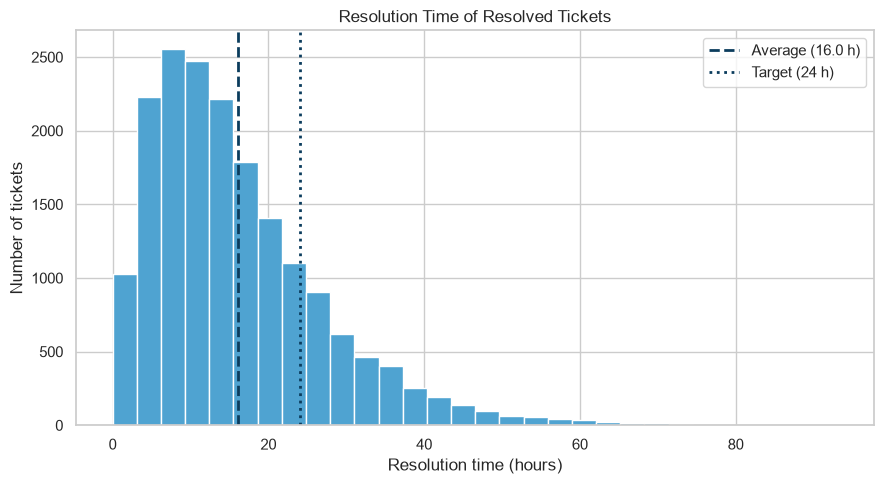

In [9]:
# only resolved tickets have a resolution time
resolved = support_tickets[support_tickets["resolution_hours"].notnull()]

avg_hours = resolved["resolution_hours"].mean()
median_hours = resolved["resolution_hours"].median()
over_24 = (resolved["resolution_hours"] > 24).sum()

print("Resolved tickets:", len(resolved))
print("Average resolution time:", round(avg_hours, 2), "hours")
print("Median resolution time:", round(median_hours, 2), "hours")
print("Tickets taking more than 24 hours:", over_24, "(", round(over_24 / len(resolved) * 100, 2), "%)")
print("Tickets without a resolution time:", support_tickets["resolution_hours"].isnull().sum())

# does priority change the time?
print(resolved.groupby("priority")["resolution_hours"].mean().round(2))

plt.figure(figsize=(9, 5))
plt.hist(resolved["resolution_hours"], bins=30, color=light_color, edgecolor="white")
plt.axvline(avg_hours, color=dark_color, linestyle="--", linewidth=2, label="Average (" + str(round(avg_hours, 1)) + " h)")
plt.axvline(24, color=dark_color, linestyle=":", linewidth=2, label="Target (24 h)")
plt.title("Resolution Time of Resolved Tickets")
plt.xlabel("Resolution time (hours)")
plt.ylabel("Number of tickets")
plt.legend()
plt.tight_layout()
plt.savefig("kpi8_resolution_time.png", dpi=150)
plt.show()

### Observation
For the 18,124 tickets that were resolved, the average resolution time is 16.04 hours (median 13.5 hours), which is better than the 24-hour target. However, about 20% of resolved tickets (3,603) took more than 24 hours. Resolution time is almost the same for every priority level (about 16 hours), which suggests that Critical and High priority tickets are not being handled faster than Low priority ones. Also, this average only covers resolved tickets, and the 13,366 tickets that are still pending, escalated or reopened have no resolution time, so the real customer experience is worse than this figure suggests. Setting faster targets for Critical tickets would be a quick improvement.

## KPI 9 – Contract Renewal Rate

**Contract Renewal Rate** = Contracts Renewed / Contracts Due for Renewal × 100

Target: above 88% for postpaid and fibre contracts.

Contracts with a known renewal outcome (Renewed, Auto-Renewed, Not Renewed or Cancelled) are treated as due for renewal. Contracts that are still Active or Pending have no outcome yet, so they are excluded.

renewal_status
Renewed         3676
Auto-Renewed    2266
Active          1829
Pending         1360
Not Renewed     1058
Cancelled        418
Name: count, dtype: int64
Due for renewal: 7418 | Renewed: 5942 | Renewal rate: 80.1 %
                  sum  count  renewal_rate_%
contract_type                               
Smart Home        192    277           69.31
IoT Solutions     288    404           71.29
Postpaid Mobile  2070   2719           76.13
Fiber Broadband  1172   1518           77.21
Prepaid Mobile   1749   1979           88.38
Enterprise        471    521           90.40
Postpaid + Fibre renewal rate: 76.52 %
renewed
False    100.0
True       0.0
Name: customer_status, dtype: float64


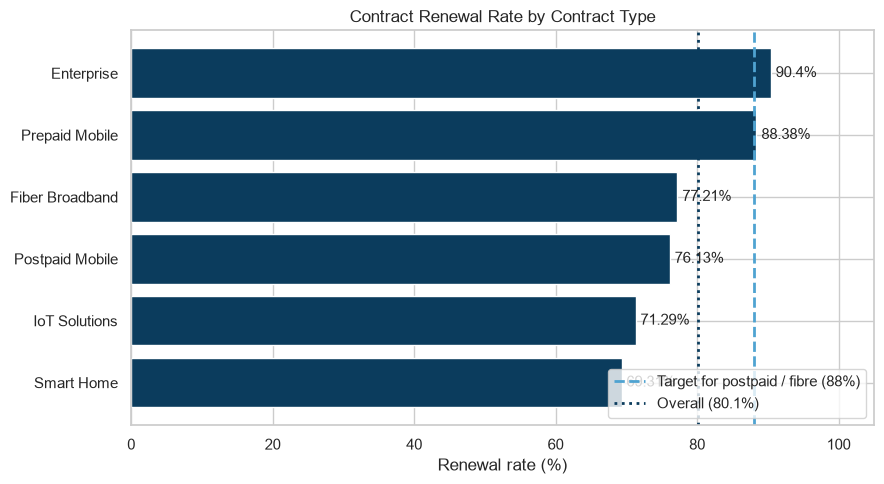

In [10]:
print(contracts["renewal_status"].value_counts())

# contracts with a known renewal outcome
due = contracts[contracts["renewal_status"].isin(["Renewed", "Auto-Renewed", "Not Renewed", "Cancelled"])].copy()
due["renewed"] = due["renewal_status"].isin(["Renewed", "Auto-Renewed"])

due_count = len(due)
renewed_count = due["renewed"].sum()
renewal_rate = renewed_count / due_count * 100
print("Due for renewal:", due_count, "| Renewed:", renewed_count, "| Renewal rate:", round(renewal_rate, 2), "%")

# renewal rate by contract type
by_type = due.groupby("contract_type")["renewed"].agg(["sum", "count"])
by_type["renewal_rate_%"] = (by_type["sum"] / by_type["count"] * 100).round(2)
by_type = by_type.sort_values("renewal_rate_%")
print(by_type)

# the target applies to postpaid and fibre
target_types = due[due["contract_type"].isin(["Postpaid Mobile", "Fiber Broadband"])]
print("Postpaid + Fibre renewal rate:", round(target_types["renewed"].mean() * 100, 2), "%")

# link with churn
due_customers = due.merge(customers[["customer_id", "customer_status"]], on="customer_id", how="left")
print(due_customers.groupby("renewed")["customer_status"].apply(lambda s: round((s == "Churned").mean() * 100, 2)))

plt.figure(figsize=(9, 5))
plt.barh(by_type.index, by_type["renewal_rate_%"], color=dark_color)
for i in range(len(by_type)):
    plt.text(by_type["renewal_rate_%"].values[i] + 0.7, i, str(by_type["renewal_rate_%"].values[i]) + "%", va="center", fontsize=11)
plt.axvline(88, color=light_color, linestyle="--", linewidth=2, label="Target for postpaid / fibre (88%)")
plt.axvline(renewal_rate, color=dark_color, linestyle=":", linewidth=2, label="Overall (" + str(round(renewal_rate, 1)) + "%)")
plt.xlim(0, 105)
plt.title("Contract Renewal Rate by Contract Type")
plt.xlabel("Renewal rate (%)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("kpi9_renewal_rate.png", dpi=150)
plt.show()

### Observation
Of the 7,418 contracts that were due for renewal, 5,942 were renewed, giving a contract renewal rate of 80.10%. For postpaid and fibre contracts, which have a target of 88%, the renewal rate is only 76.52% (Postpaid Mobile 76.13% and Fiber Broadband 77.21%), so both are clearly below target. Enterprise (90.40%) and Prepaid Mobile (88.38%) are above 88%, while Smart Home (69.31%) and IoT Solutions (71.29%) have the lowest renewal rates. Renewal is also closely connected to churn: every contract that was not renewed or was cancelled belongs to a customer who has churned, while none of the renewed contracts do. This means the renewal date is the key moment to save a customer, so offers and outreach should start before the contract ends, especially for postpaid and fibre customers. Whether a contract has auto-renew switched on makes little difference (80.63% with auto-renew compared with 79.50% without).

## KPI 10 – Average Customer Tenure

**Average Customer Tenure** = Mean of tenure_months for the active customer base

A rising tenure indicates that customers are staying longer.

Active customers: 15494
Average tenure: 87.08 months = 7.3 years
Median tenure: 90.0 months
Churned customers average tenure: 32.1 months
customer_segment
Enterprise    94.99
Premium       88.59
Value         87.50
Mass          76.52
Name: tenure_months, dtype: float64
  quarter_end  active_customers  avg_tenure_months
0  2024-03-31             14783              70.60
1  2024-06-30             14982              72.25
2  2024-09-30             15202              73.84
3  2024-12-31             15364              75.66
4  2025-03-31             15515              77.42
5  2025-06-30             15627              79.48
6  2025-09-30             15714              81.50
7  2025-12-31             15752              83.81
8  2026-03-31             15494              87.64


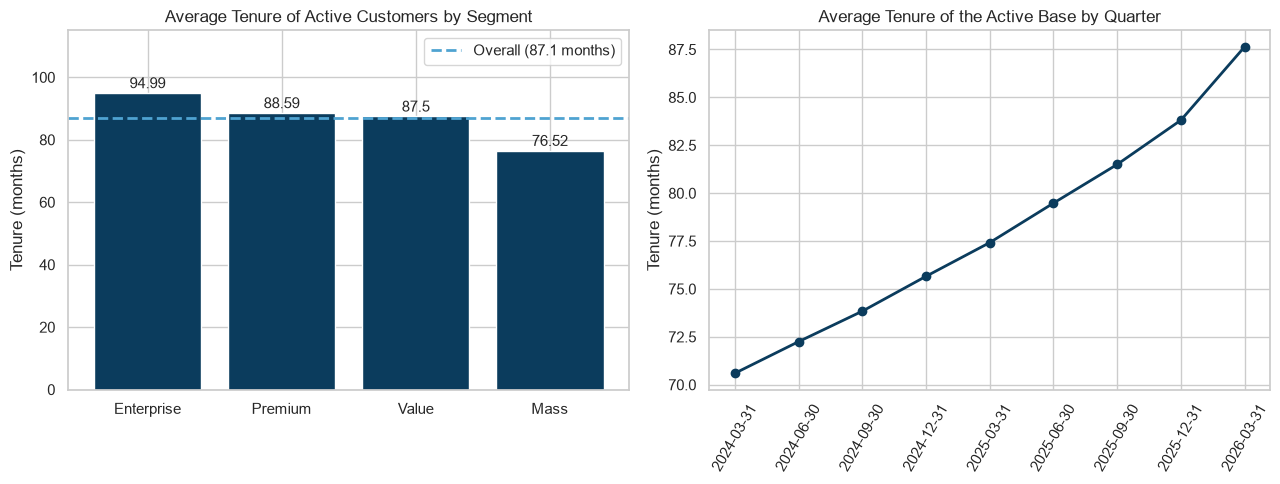

In [11]:
active = customers[customers["customer_status"] == "Active"]
avg_tenure = active["tenure_months"].mean()
print("Active customers:", len(active))
print("Average tenure:", round(avg_tenure, 2), "months =", round(avg_tenure / 12, 1), "years")
print("Median tenure:", active["tenure_months"].median(), "months")
print("Churned customers average tenure:", round(customers[customers["customer_status"] == "Churned"]["tenure_months"].mean(), 2), "months")

# tenure by segment
tenure_segment = active.groupby("customer_segment")["tenure_months"].mean().round(2).sort_values(ascending=False)
print(tenure_segment)

# average tenure of the active base at the end of each quarter
rows = []
for quarter_end in pd.date_range("2024-03-31", "2026-03-31", freq="QE"):
    base = customers[(customers["acquisition_date"] <= quarter_end) & (customers["churn_date"].isnull() | (customers["churn_date"] > quarter_end))]
    months = (quarter_end - base["acquisition_date"]).dt.days / 30.44
    rows.append([str(quarter_end.date()), len(base), round(months.mean(), 2)])
trend = pd.DataFrame(rows, columns=["quarter_end", "active_customers", "avg_tenure_months"])
print(trend)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(tenure_segment.index, tenure_segment.values, color=dark_color)
for i in range(len(tenure_segment)):
    axes[0].text(i, tenure_segment.values[i] + 1.5, str(tenure_segment.values[i]), ha="center", fontsize=11)
axes[0].axhline(avg_tenure, color=light_color, linestyle="--", linewidth=2, label="Overall (" + str(round(avg_tenure, 1)) + " months)")
axes[0].set_ylim(0, tenure_segment.max() + 20)
axes[0].set_title("Average Tenure of Active Customers by Segment")
axes[0].set_ylabel("Tenure (months)")
axes[0].legend()

axes[1].plot(trend["quarter_end"], trend["avg_tenure_months"], color=dark_color, marker="o", linewidth=2)
axes[1].set_title("Average Tenure of the Active Base by Quarter")
axes[1].set_ylabel("Tenure (months)")
axes[1].tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.savefig("kpi10_tenure.png", dpi=150)
plt.show()

### Observation
The average active customer has been with the company for 87.08 months (about 7.3 years), compared with 32.10 months for customers who have churned. Tenure is highest for Enterprise customers (94.99 months) and lowest for Mass customers (76.52 months), which matches the segment churn pattern seen earlier. Average tenure of the active base has risen every quarter, from 70.6 months in March 2024 to 87.6 months in March 2026. On its face this suggests improving stickiness, but part of the rise comes from an ageing base: fewer new customers have been joining recently (for example 90 in February 2026 against 135 in October 2025), so the average is pulled up by long-standing customers. This is not purely good news, because with rising churn and slowing acquisition the customer base could start to shrink.

## Overall KPI Summary & Insights

| # | KPI | Result | Target | Status |
|---|-----|--------|--------|--------|
| 1 | Monthly churn rate | 1.26% (Mar-26); 0.67% 12-month average | < 2.1% | Within target, rising fast |
| 2 | Retention rate | 98.74% (Mar-26); 99.33% 12-month average | – | High, but falling |
| 3 | ARPU | ₹950 per month | – | Enterprise ₹4,088 · Premium ₹909 · Value ₹496 · Mass ₹339 |
| 4 | Customer Lifetime Value | ₹98,849 (70% margin assumed) | – | Enterprise ₹6.56 lakh · Premium ₹1.24 lakh · Value ₹44.7k · Mass ₹21.9k |
| 5 | Revenue lost to churn | ₹25.7 lakh per month (all 3,506 churned customers); ₹9.0 lakh per month for the last 12 months | – | Premium is 49.8% of the loss |
| 6 | MRR | ₹1.47 crore (annual run rate ₹17.66 crore) | – | Premium 44.5%, Enterprise 34.0% |
| 7 | First Contact Resolution | 40.41% | > 78% | Not met |
| 8 | Average resolution time | 16.04 hours (median 13.5) | < 24h | Met |
| 9 | Contract renewal rate | 80.10% (Postpaid + Fibre 76.52%) | > 88% | Not met |
| 10 | Average tenure (active customers) | 87.08 months (7.3 years) | – | Rising, partly due to an ageing base |

### Key Insights

1. **Churn is within target but accelerating.** Monthly churn rose from 0.26% in Apr-24 to 1.26% in Mar-26, almost five times higher, with the sharpest increase in the last three months. If the trend continues, the 2.1% target could be crossed within a few months.
2. **Revenue is concentrated in a few segments.** Premium and Enterprise bring in 78.5% of MRR while making up about 54% of active customers. Mass customers are about 14% of the active base but only 5.0% of MRR.
3. **Churn rate and revenue loss point to different segments.** Mass churns the most (1.08% per month) but costs the least revenue. Premium loses the most revenue (49.8% of the total), so retention spending should follow revenue at risk, not only churn rate.
4. **Customer value differs enormously by segment.** An Enterprise customer is worth about 30 times a Mass customer (₹6.56 lakh vs ₹21.9k), because they pay more per month and stay longer.
5. **Support quality is the weakest area.** Only 40.41% of tickets are resolved on first contact against a 78% target, and 42.44% of tickets are still pending, escalated or reopened. The problem is the same across all ticket categories, so it is a process issue, not one problem type.
6. **Poor first-contact resolution is linked to churn.** Customers whose tickets were not fixed first time churned more (22.10% vs 18.83%).
7. **Average resolution time hides problems.** The 16.04-hour average meets target, but about 20% of resolved tickets took more than 24 hours. Critical tickets are not handled faster than Low ones (about 16 hours for every priority), and the 13,366 open tickets have no resolution time at all.
8. **Renewals are the key moment to save a customer.** Every contract that was not renewed or was cancelled belongs to a churned customer. Postpaid (76.13%) and Fibre (77.21%) are well below the 88% target, and Smart Home (69.31%) and IoT (71.29%) renew least.
9. **Tenure is rising, but that is not fully good news.** Average tenure of the active base rose from 70.6 to 87.6 months in two years, partly because fewer new customers are joining (90 in Feb-26 vs 135 in Oct-25). With rising churn and slower acquisition, the base could start to shrink.
10. **Lifetime value is likely overstated.** CLV uses the 12-month average churn of 0.67%. Using the latest monthly churn of 1.26% would cut overall CLV to roughly ₹52,800.

### Recommendations

1. **Protect Premium and Enterprise first.** Set up early-warning alerts and dedicated account support for these customers, since they hold most of the revenue and lifetime value.
2. **Fix first-contact resolution.** Train agents, give them better tools, and clear the backlog of pending, escalated and reopened tickets. Set faster targets for Critical tickets.
3. **Run renewal campaigns before contracts end,** starting with Postpaid, Fibre, Smart Home and IoT customers.
4. **Add a stronger onboarding and Mass-segment offer** to reduce early churn in the lowest-value, highest-churn segment.
5. **Track monthly churn closely** against the 2.1% target, and report revenue at risk alongside churn rate.

### Assumptions & Limitations
- Gross margin of 70% is assumed because the dataset does not contain it.
- Churn, retention and CLV use the period Apr-25 to Mar-26. March 2026 has only 4 new customers because the data ends there.
- Resolution time covers resolved tickets only.